# 3.3.0-Clustering Level 2

**Inés Sentís**

Date of execution

In [1]:
Sys.Date()

[1] "2026-02-05"

## Libraries

In [2]:
options(warn = -1, verbose = FALSE)
suppressMessages(suppressWarnings({
library(Signac)
library(Seurat)
library(tidyverse)
library(ggplot2)
library(gridExtra)
library(scran)
library(scater)
}))

## Parameters

In [3]:
patient <- "p2"
subproj <- "AVGUSTINOVA_12_13"

In [4]:
source(here::here(glue::glue("{subproj}/multiome_analysis/misc/paths.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/style.R")))
source(here::here(glue::glue("{subproj}/multiome_analysis/utils/variables.R")))
source(here::here(glue::glue("utils/bin.R")))

"{clust}/{plt_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

"{clust}/{robj_dir}/level_2" %>%
  glue::glue() %>%
  here::here() %>%
  dir.create(path = .,
           showWarnings = FALSE,
           recursive = TRUE)

set.seed(0)

In [5]:
var_name <- paste0("colors_", patient)
colors_list <- get(var_name)

In [6]:
var_name <- paste0("comp_", patient)
dcomp <- get(var_name)
dcomp

$rna
 [1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

$atac
 [1]  2  3  4  5  6  7  8  9 10 11 12 13 14 15

In [7]:
var_name <- paste0("topc_", patient)
top_counts <- get(var_name)
top_counts

[1] "NFIA"     "RABGAP1L" "AFF3"     "CACNA2D3" "LSAMP"    "SLIT2"   
 [7] "PCDH7"    "INPP4B"   "TENM3"    "FBXL7"    "ADGRV1"   "TENM2"   
[13] "PHACTR2"  "ARID1B"   "CRPPA"    "KANK1"    "RFX3"     "GLIS3"   
[19] "TRPM3"    "KIAA1217" "PRKG1"    "NEAT1"    "MALAT1"   "CADM1"   
[25] "HMGA2"    "RMST"     "MTUS2"    "TSC22D1"  "NPAS3"    "OTX2-AS1"
[31] "SNHG14"   "RORA"     "MIR99AHG" "FTX"      "XACT"     "HTR2C"

In [8]:
var_name <- paste0("reso_l1_", patient)
reso <- get(var_name)

## Load data

In [9]:
seurat_obj <- readRDS(here::here(glue::glue("{clust}/{robj_dir}/level_1/3.2.0-l1_anno_{patient}.rds")))

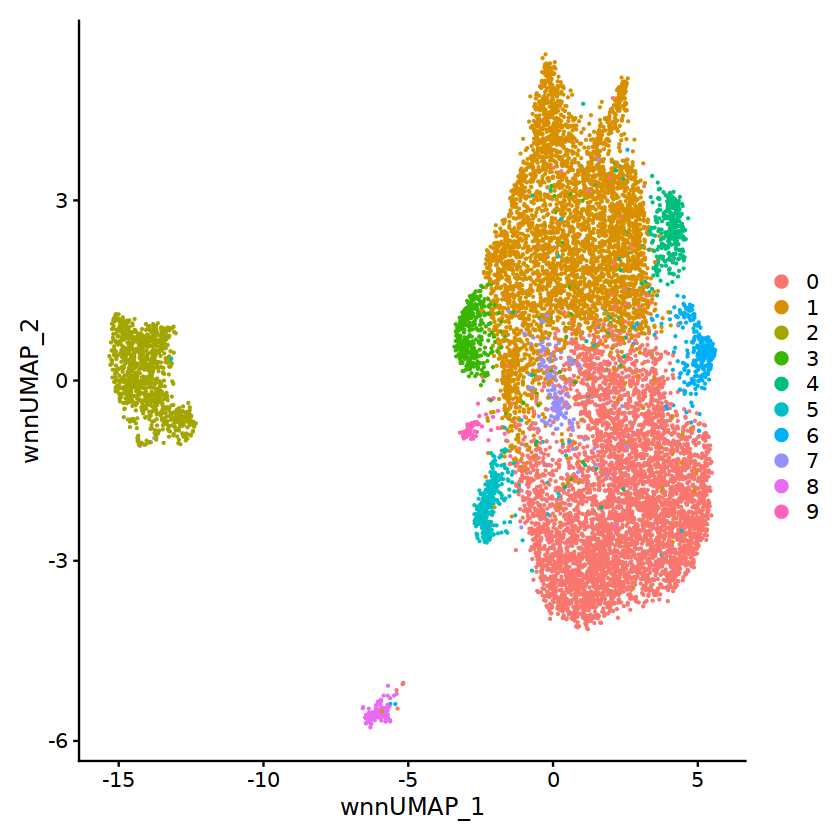

In [10]:
DimPlot(seurat_obj, reduction = "wnn.umap") 

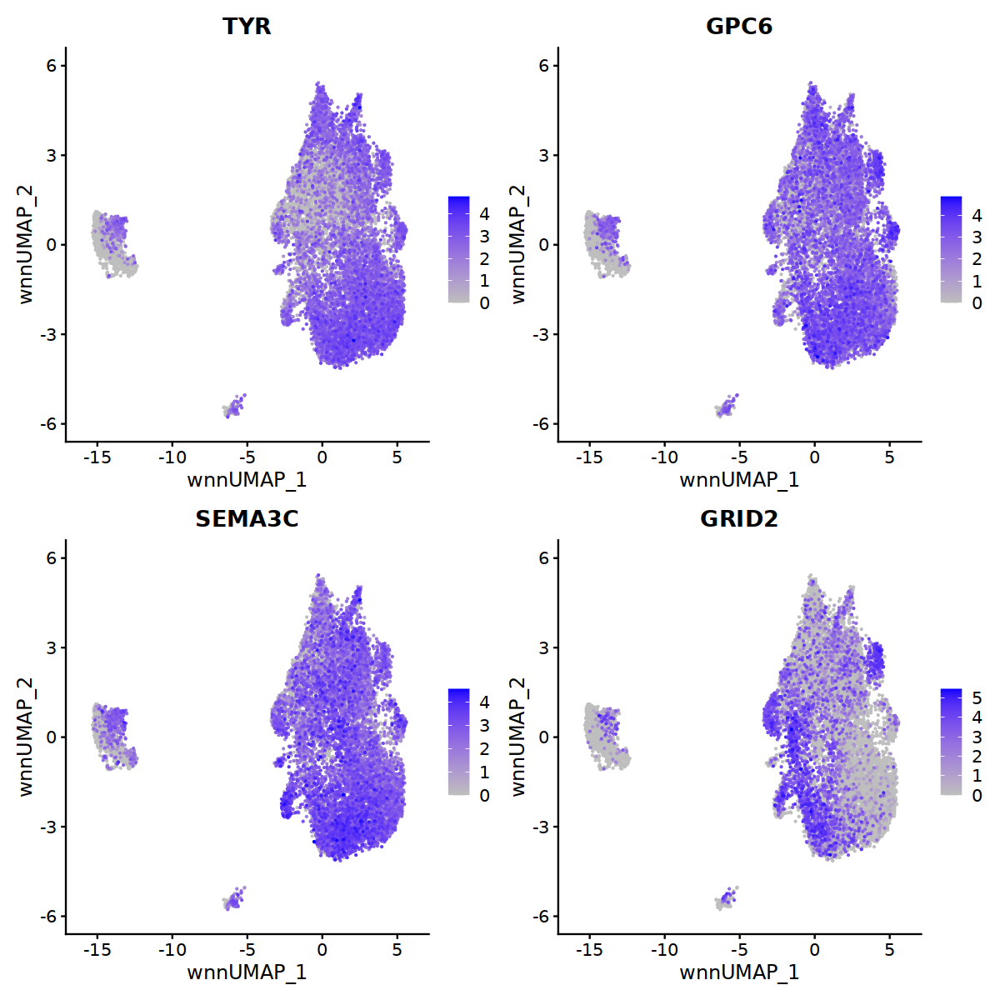

In [11]:
options(repr.plot.width = 10, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("TYR","GPC6", "SEMA3C", 
                              "GRID2"),ncol=2,
            cols = c("gray", "blue"),  order=T)

## Re-normalize

Check whether DecontX has fixed enough the TYR expression in immune cells 

In [12]:
assay_ch <- "RNA_decontx"
DefaultAssay(seurat_obj) <- assay_ch

In [13]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [14]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [15]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj, assay=assay_ch)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

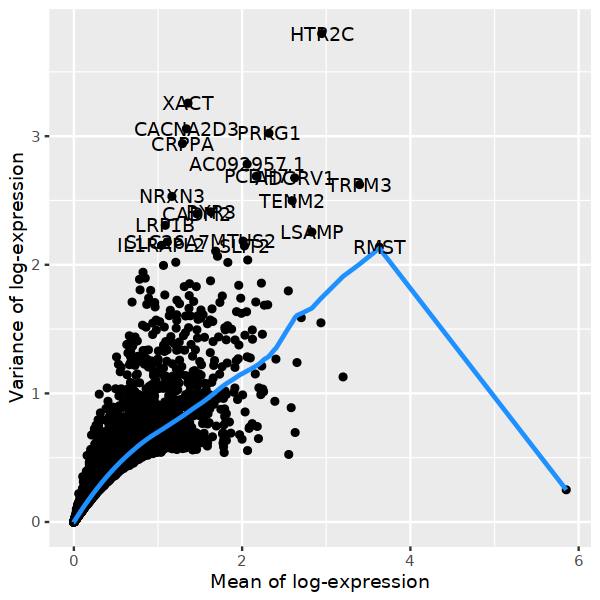

In [16]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [17]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 1024
[1] 1014


In [18]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  AC092957.1, SGO1-AS1, ADGRL3, DCDC2, GPC6, LAMB1, PTPRD, RYR3, TYR, DNAH7 
	   SLC4A10, MAP2, SEMA5A, NTNG1, MAGI2, EBF1, LINC00882, NCAM2, SORCS3, SYT14 
	   SHROOM3, CALCRL, CADM2, AC016152.1, GALNT17, NEGR1, CSMD3, DMD, SLC26A7, NETO2 
Negative:  DOCK4, ELMO1, ZEB2, CHST11, CD163, FMN1, LNCAROD, MSR1, RGS1, SLC1A3 
	   FYB1, TLR2, DOCK2, ARHGAP18, MGAT4A, SLCO2B1, DPYD, KCNQ3, PTPRC, CTSB 
	   TBXAS1, APBB1IP, LRMDA, SKAP2, LINC00278, ARHGAP15, ADAM28, SAMSN1, ARHGAP26, ITPR2 
PC_ 2 
Positive:  LINC01687, AC078845.1, KCNN2, GRIK1, TYR, SLC26A7, SLC38A11, ARMC3, EML5, DNAH7 
	   USP53, AC019197.1, GREB1L, AC092957.1, AC009975.2, TLN2, NETO2, SYT14, AC138627.1, SGCZ 
	   RIMS2, ZFPM2, CALCRL, EBF1, GNAL, SLC8A1, PRELID2, AC106793.1, TRPM1, MARCH1 
Negative:  NRXN3, SHROOM3, LHFPL6, ERBB4, THRB, PCSK6, CELF2, CDH11, SOX5, MCTP1 
	   NKAIN3, TOX, UACA, GRM8, SORBS2, FMNL2, TNIK, SV2C, LINGO2, ADAMTS6 
	   DOK6, DST, NAV2, LYPD6B, AC10

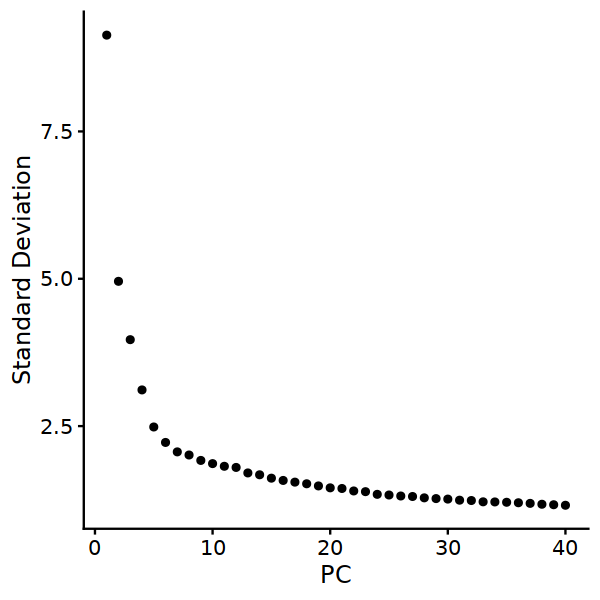

In [19]:
ElbowPlot(seurat_obj, n=40)

In [20]:
seurat_obj <- RunUMAP(
  seurat_obj,
  dims = dcomp$rna,
  reduction = "pca",
  reduction.key = "rnaUMAP_",
   assay.use = assay_ch,
)

Suggested parameter: assay instead of assay.use


14:37:48 UMAP embedding parameters a = 0.9922 b = 1.112

14:37:48 Read 11727 rows and found 20 numeric columns

14:37:48 Using Annoy for neighbor search, n_neighbors = 30

14:37:48 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

14:37:50 Writing NN index file to temp file /scratch_tmp/53746958/RtmpelEm02/file434613babf4b

14:37:50 Searching Annoy index using 1 thread, search_k = 3000

14:37:53 Annoy recall = 100%

14:37:54 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

14:37:54 11 smooth knn distance failures

14:37:56 Initializing from normalized Laplacian + noise (using irlba)

14:37:56 Commencing optimization for 200 epochs, with 476340 positive edges

14:38:10 Optimization f

In [21]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [22]:
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

14:38:44 UMAP embedding parameters a = 0.9922 b = 1.112

14:38:44 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:38:46 Initializing from normalized Laplacian + noise (using irlba)

14:38:46 Commencing optimization for 200 epochs, with 343084 positive edges

14:39:01 Optimization finished



In [23]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 11727
Number of edges: 355376

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9736
Number of communities: 11
Elapsed time: 1 seconds


1 singletons identified. 10 final clusters.



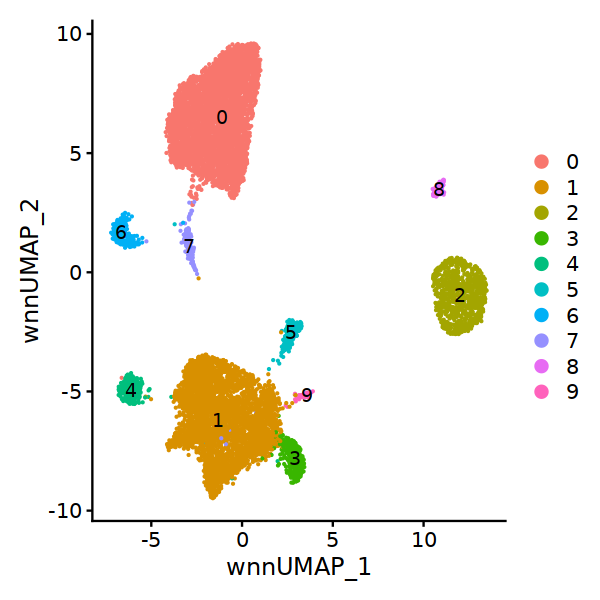

In [24]:
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

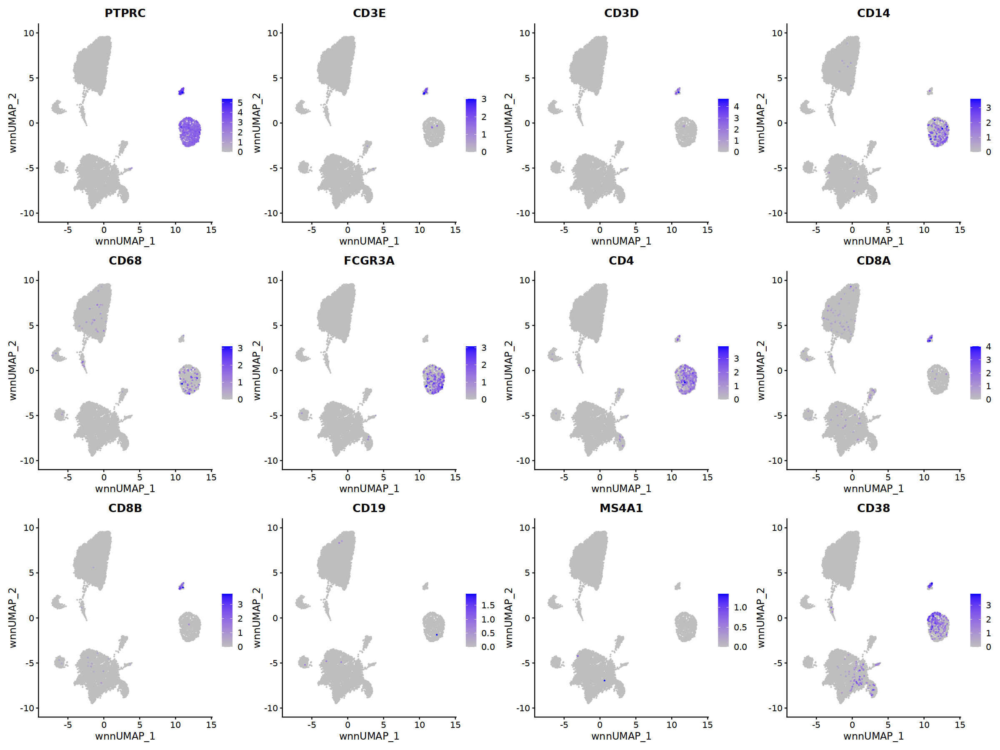

In [25]:
options(repr.plot.width = 20, repr.plot.height = 15)
immune <- c("PTPRC","CD3E", "CD3D", "CD14", "CD68", "FCGR3A", "CD4", "CD8A", "CD8B", "CD19", 
            "MS4A1", "CD38")

vars2plot <- exp_genes_plot(immune, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

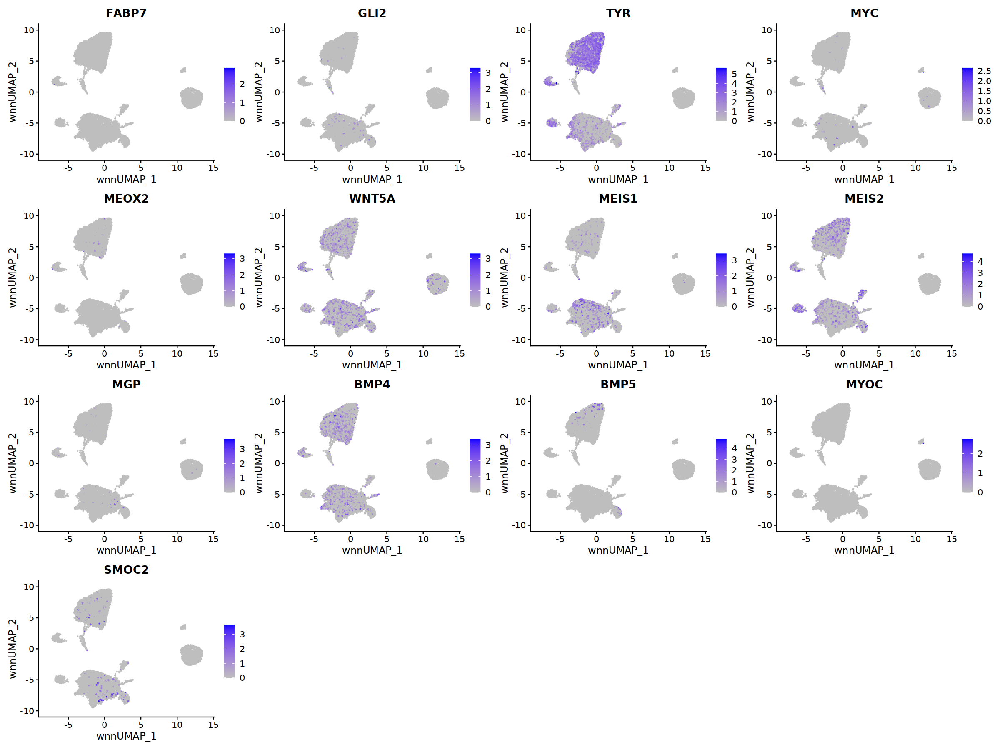

In [26]:
options(repr.plot.width = 20, repr.plot.height = 15)
lite_tumor <- c("FABP7", "GLI2", "TYR", "MYC", "MEOX2", "WNT5A", "MEIS1", 
                "MEIS2", "MGP", "BMP4", "BMP5", "MYOC", "SMOC2")

vars2plot <- exp_genes_plot(lite_tumor, seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),  min.cutoff = 0)

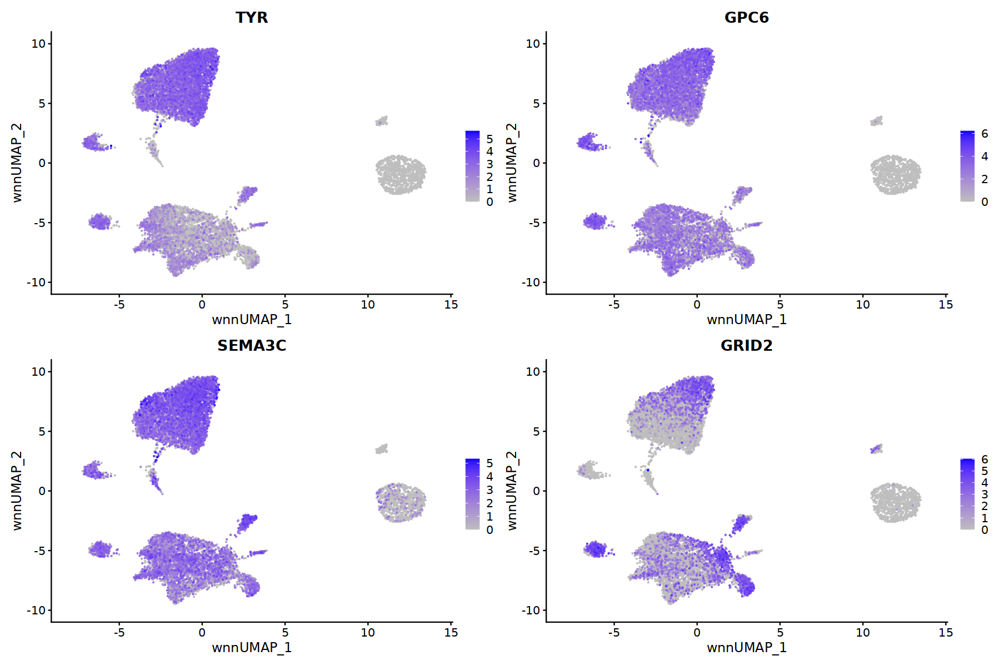

In [27]:
options(repr.plot.width = 15, repr.plot.height = 10)
FeaturePlot(seurat_obj, reduction = "wnn.umap", 
            feature=c("TYR","GPC6", "SEMA3C", 
                              "GRID2"),ncol=2,
            cols = c("gray", "blue"),  order=T)

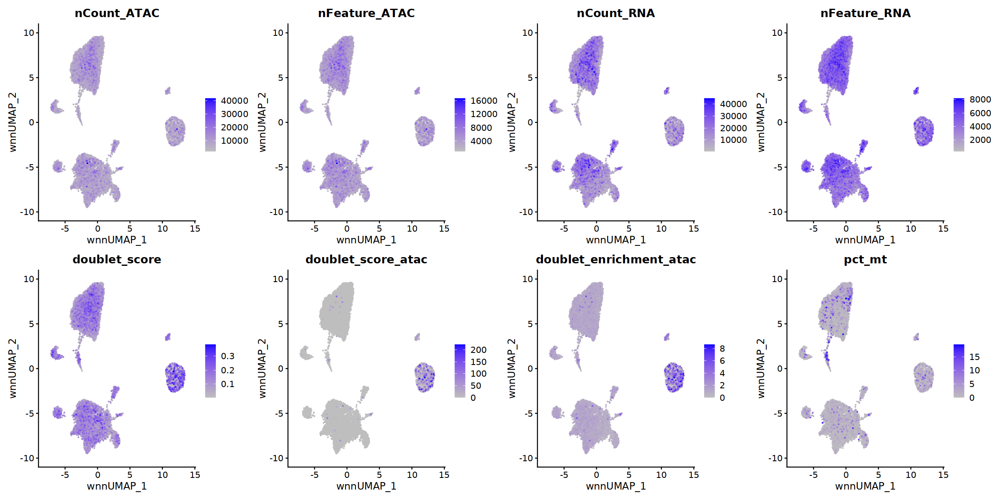

In [28]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

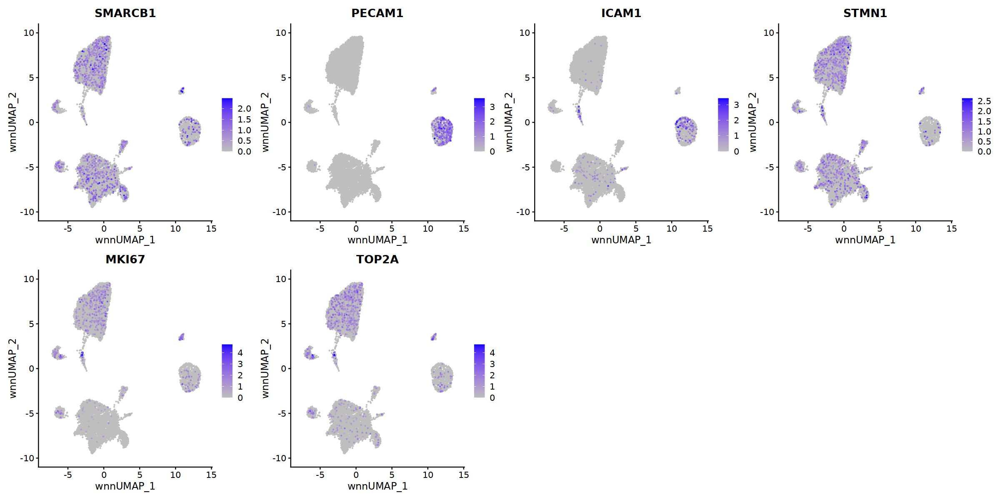

In [29]:
options(repr.plot.width = 20, repr.plot.height = 10)
other <- c("SMARCB1", "PECAM1","ICAM1","STMN1","MKI67","TOP2A")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=other, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

In [30]:
rna.markers <- FindAllMarkers(seurat_obj, only.pos = TRUE, 
                              min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9



In [31]:
rna.markers %>% 
  dplyr::filter(cluster == "7") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
BIRC3,9.884394e-30,2.476124,0.102,0.012,3.223499e-25,7,BIRC3
GPC52,8.706797e-11,2.380273,0.215,0.092,2.839461e-06,7,GPC5
FTL1,6.885590e-12,2.260886,0.317,0.167,2.245529e-07,7,FTL
FTH11,3.082900e-08,1.878184,0.278,0.163,1.005395e-03,7,FTH1
B2M1,5.090643e-13,1.636445,0.327,0.166,1.660161e-08,7,B2M
TPT11,1.067077e-06,1.627885,0.322,0.231,3.479953e-02,7,TPT1
HLA-B1,2.830202e-10,1.554635,0.141,0.048,9.229855e-06,7,HLA-B
PPP1R15A1,1.877112e-10,1.358387,0.102,0.028,6.121639e-06,7,PPP1R15A
STXBP5L2,1.991515e-11,1.192135,0.015,0.208,6.494729e-07,7,STXBP5L


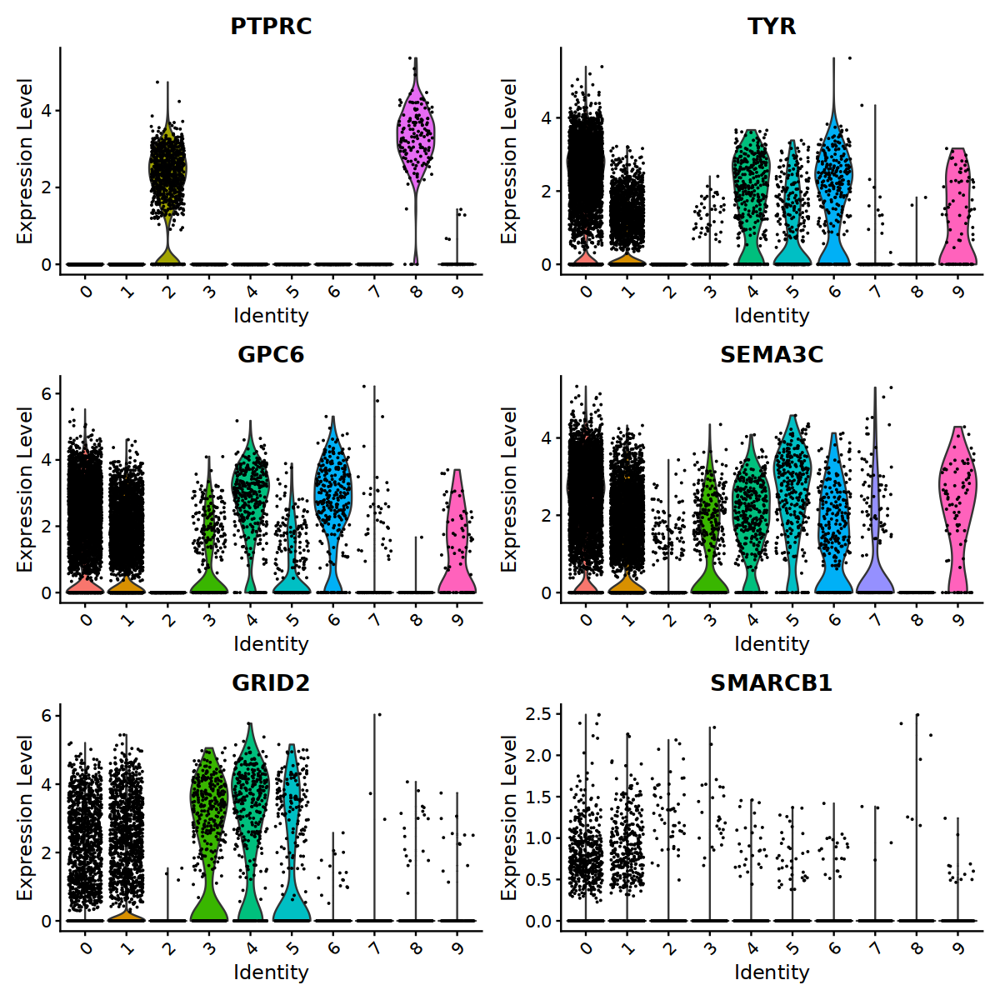

In [32]:
options(repr.plot.width = 10, repr.plot.height = 10)
VlnPlot(seurat_obj, 
            feature=c("PTPRC", "TYR","GPC6", "SEMA3C", 
                              "GRID2", "SMARCB1"),ncol=2)

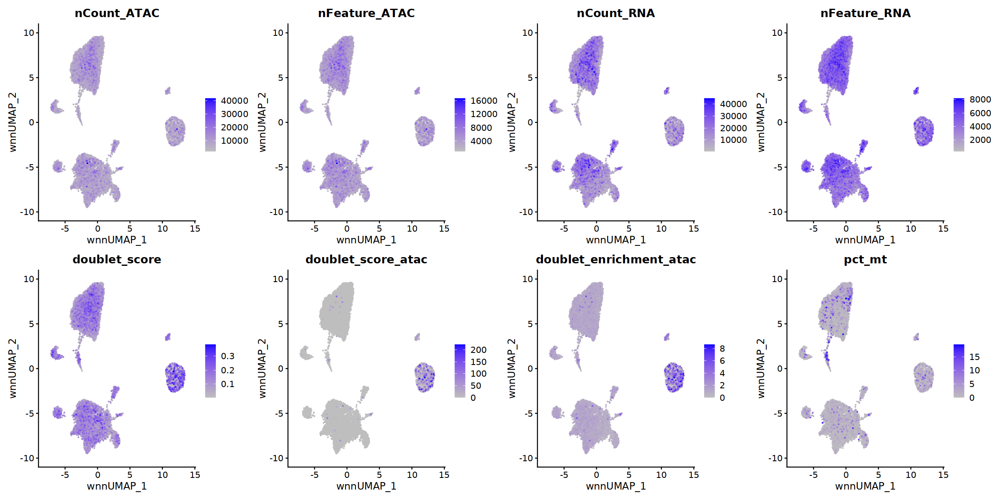

In [33]:
options(repr.plot.width = 20, repr.plot.height = 10)
qc_vars <- c('nCount_ATAC','nFeature_ATAC','nCount_RNA','nFeature_RNA',
             "doublet_score","doublet_score_atac",
             "doublet_enrichment_atac", "pct_mt")


FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=qc_vars, ncol = 4, 
            cols = c("gray", "blue"), min.cutoff = 0, order=T)

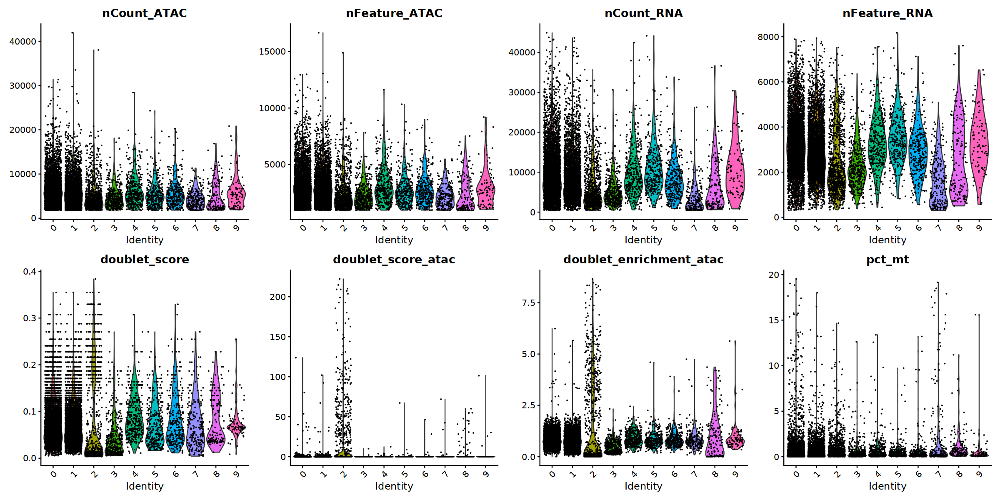

In [34]:
VlnPlot(seurat_obj, feature=qc_vars, ncol = 4)

## Filter cells

In [35]:
seurat_obj <- subset(seurat_obj, idents = c("7"), invert = TRUE)

In [36]:
keep_genes <- data.frame(rowSums(as.matrix(seurat_obj[[assay_ch]]@counts)) != 0)
colnames(keep_genes) <- "logical"
keep_genes <- subset(keep_genes, logical==TRUE)
seurat_obj[[assay_ch]]@counts <- seurat_obj[[assay_ch]]@counts[rownames(keep_genes), ]
seurat_obj[[assay_ch]]@data <- seurat_obj[[assay_ch]]@data[rownames(keep_genes), ]

In [37]:
keep_peaks <- data.frame(rowSums(as.matrix(seurat_obj[['ATAC']]@counts)) >= 1)
colnames(keep_peaks) <- "logical"
keep_peaks <- subset(keep_peaks, logical==TRUE)
seurat_obj[['ATAC']]@counts <- seurat_obj[['ATAC']]@counts[rownames(keep_peaks), ]
seurat_obj[['ATAC']]@data <- seurat_obj[['ATAC']]@data[rownames(keep_peaks), ]

### RNA

In [38]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- NormalizeData(
  seurat_obj,
  normalization.method = "LogNormalize",
  scale.factor = 1e4
)

In [39]:
# compute the variance and mean of the log-expression values 
sce <- as.SingleCellExperiment(seurat_obj)
gene_var <- modelGeneVar(sce)

tops <- gene_var %>% 
    as.data.frame() %>% 
    arrange(desc(total)) %>% 
    head(n=20)

plt <- gene_var %>% 
  as.data.frame() %>% 
  ggplot(aes(mean, total)) +
  geom_point() +
  geom_line(aes(y = tech), colour = "dodgerblue", size = 1) +
  labs(x = "Mean of log-expression", y = "Variance of log-expression")+
  geom_text(data=tops, aes(mean,total,label=rownames(tops)))

hvgs <- getTopHVGs(gene_var,fdr.threshold = 0.05)

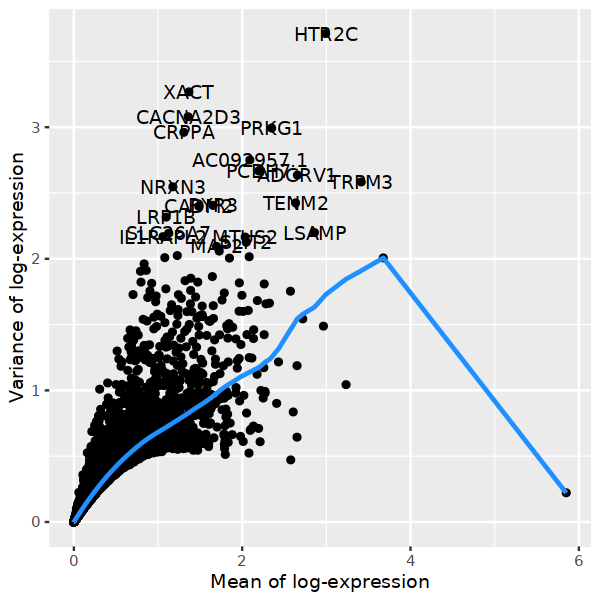

In [40]:
options(repr.plot.width = 5, repr.plot.height = 5)
plt

In [41]:
print(length(hvgs))
hvgs <- setdiff(hvgs, top_counts)
print(length(hvgs))

[1] 982
[1] 972


In [42]:
VariableFeatures(seurat_obj) <- hvgs

seurat_obj <- seurat_obj %>%
  ScaleData() %>% 
  RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  DOCK4, ELMO1, ZEB2, CHST11, CD163, FMN1, LNCAROD, MSR1, SLC1A3, RGS1 
	   TLR2, FYB1, ARHGAP18, DOCK2, MGAT4A, DPYD, SLCO2B1, CTSB, KCNQ3, PTPRC 
	   TBXAS1, APBB1IP, LRMDA, SKAP2, LINC00278, ARHGAP15, ADAM28, ARHGAP26, SAMSN1, ITPR2 
Negative:  AC092957.1, SGO1-AS1, ADGRL3, DCDC2, GPC6, LAMB1, PTPRD, TYR, RYR3, DNAH7 
	   SLC4A10, ENOX1, MAP2, FAM126A, NTNG1, SEMA5A, MAGI2, EBF1, LINC00882, SYT14 
	   NCAM2, SORCS3, CALCRL, SHROOM3, CADM2, AC016152.1, GALNT17, LEF1, NEGR1, CSMD3 
PC_ 2 
Positive:  NRXN3, SHROOM3, LHFPL6, ERBB4, THRB, PCSK6, CELF2, SOX5, CDH11, MCTP1 
	   NKAIN3, TOX, GRM8, UACA, SORBS2, SV2C, FMNL2, TNIK, LINGO2, ADAMTS6 
	   DST, DOK6, NAV2, LYPD6B, NLGN1, AC105411.1, CUX2, GRIN2A, CALD1, ALCAM 
Negative:  LINC01687, AC078845.1, KCNN2, GRIK1, TYR, SLC26A7, SLC38A11, EML5, ARMC3, DNAH7 
	   USP53, AC019197.1, FAM126A, GREB1L, AC092957.1, AC009975.2, TLN2, NETO2, SYT14, AC138627.1 
	   SGCZ, RIMS2, ZFPM2, CALCRL, EBF

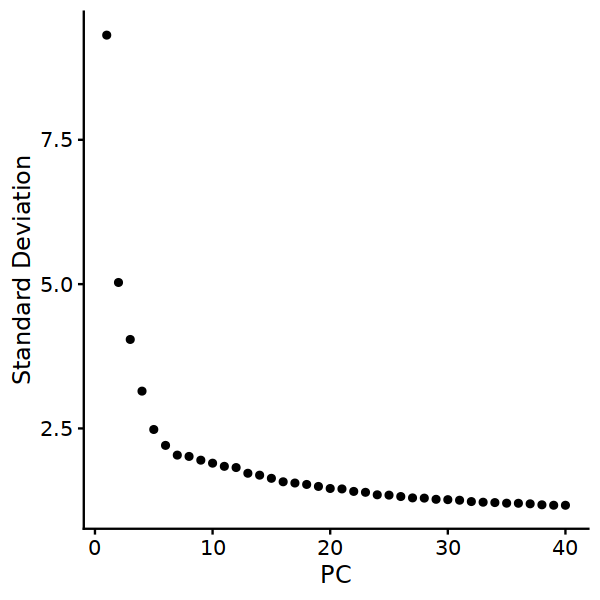

In [43]:
ElbowPlot(seurat_obj, n=40)

### ATAC

In [44]:
DefaultAssay(seurat_obj) <- "ATAC" # for individual analysis
seurat_obj <- RunTFIDF(seurat_obj)

Performing TF-IDF normalization



In [45]:
seurat_obj <- FindTopFeatures(seurat_obj, min.cutoff = "q75")
seurat_obj <- RunSVD(seurat_obj, reduction.name = "lsi.atac")

Running SVD

Scaling cell embeddings



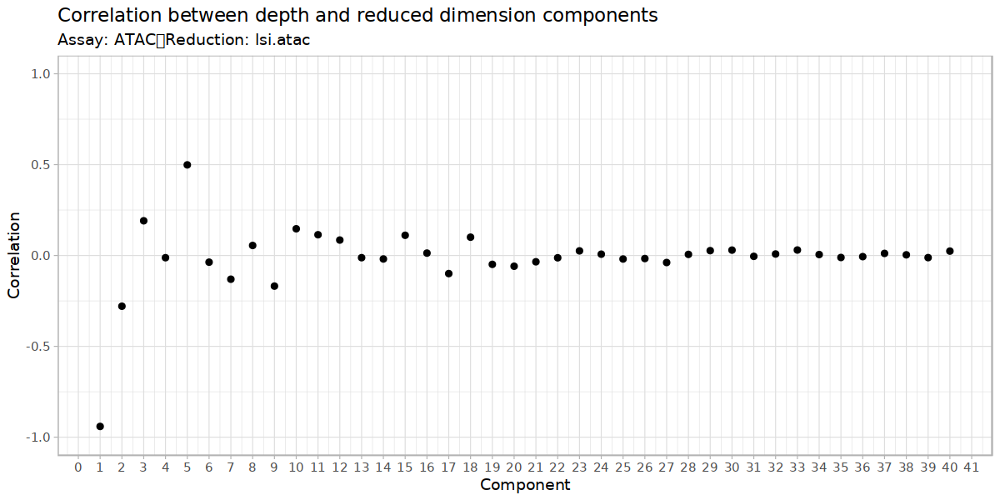

In [46]:
options(repr.plot.width = 10, repr.plot.height = 5)
DepthCor(seurat_obj, reduction = "lsi.atac", n=40)

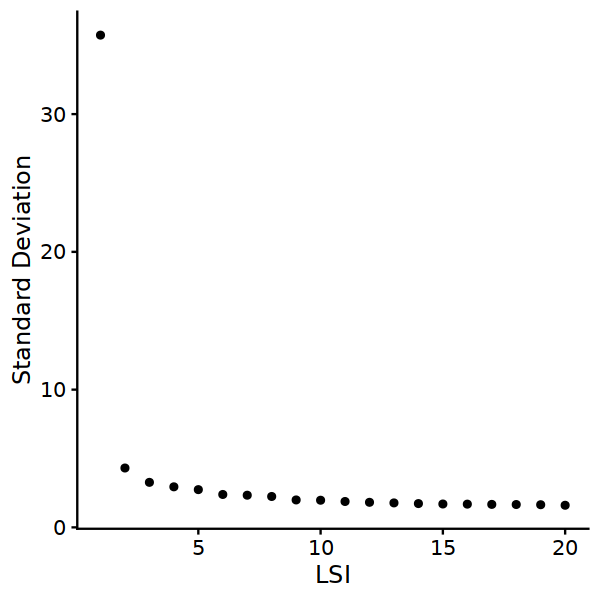

In [47]:
options(repr.plot.width = 5, repr.plot.height = 5)
ElbowPlot(seurat_obj, n=20, reduction="lsi.atac")

### Joint

In [48]:
seurat_obj <- FindMultiModalNeighbors(
 seurat_obj,
 reduction.list = list("pca", "lsi.atac"),
 dims.list = list(dcomp$rna, dcomp$atac)
)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [49]:
DefaultAssay(seurat_obj) <- assay_ch
seurat_obj <- RunUMAP(
   seurat_obj,
   nn.name = "weighted.nn",
   reduction.name = "wnn.umap",
   reduction.key = "wnnUMAP_"
)

14:49:15 UMAP embedding parameters a = 0.9922 b = 1.112

14:49:16 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

14:49:18 Initializing from normalized Laplacian + noise (using irlba)

14:49:18 Commencing optimization for 200 epochs, with 335420 positive edges

14:49:32 Optimization finished



In [50]:
seurat_obj <- Seurat::FindClusters(seurat_obj, resolution = 0.1,
                                     graph.name = "wsnn")

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 11522
Number of edges: 344692

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9733
Number of communities: 10
Elapsed time: 1 seconds


1 singletons identified. 9 final clusters.



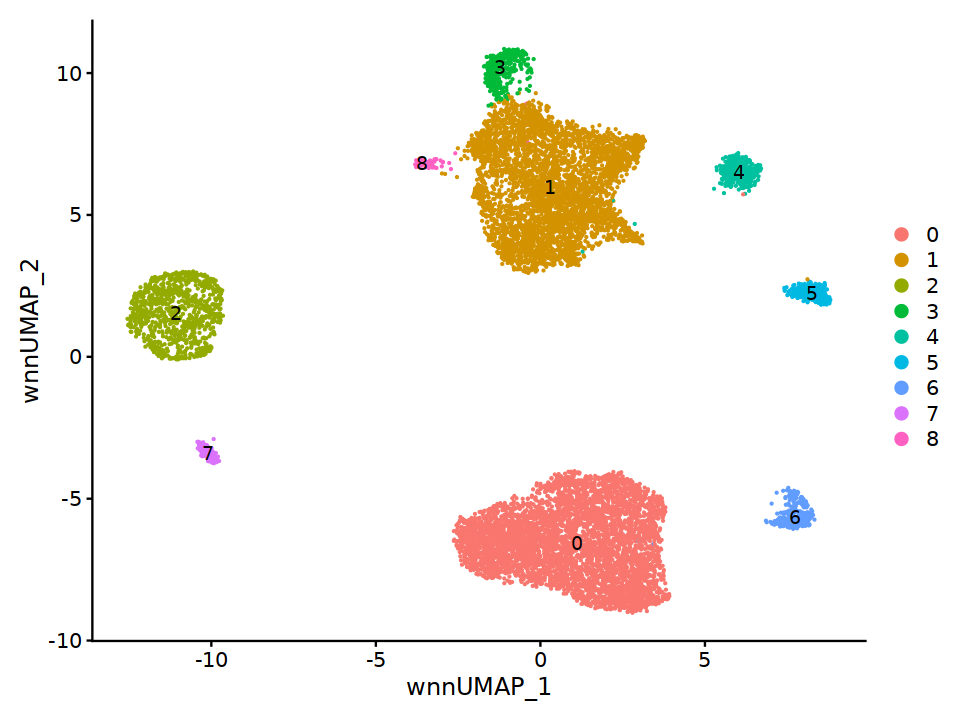

In [51]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap", label=T) 

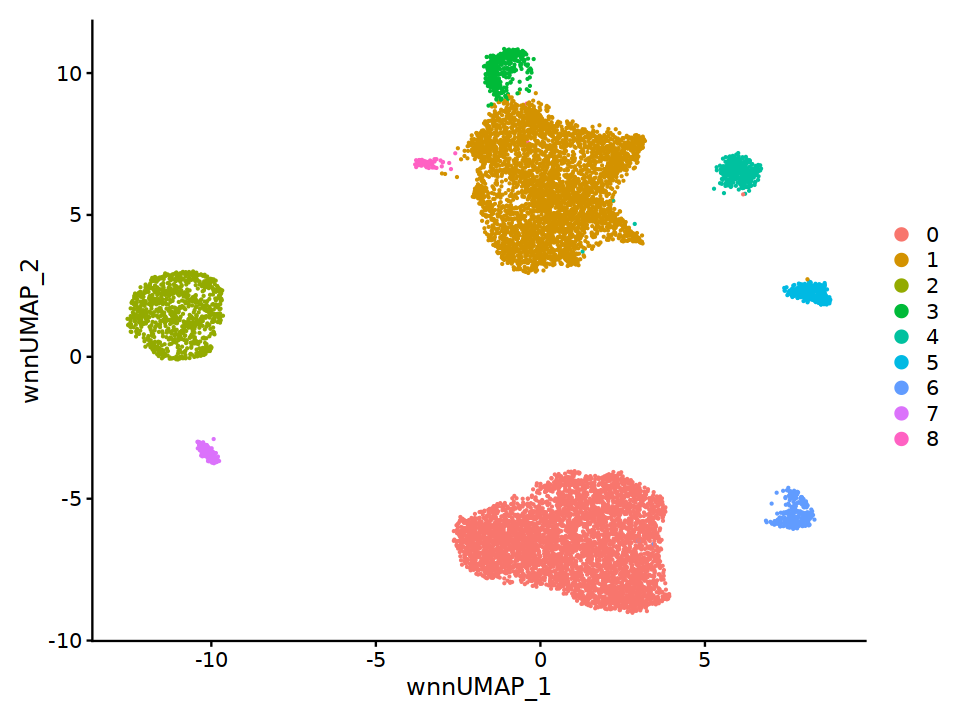

In [52]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(seurat_obj, reduction = "wnn.umap") 

In [53]:
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8



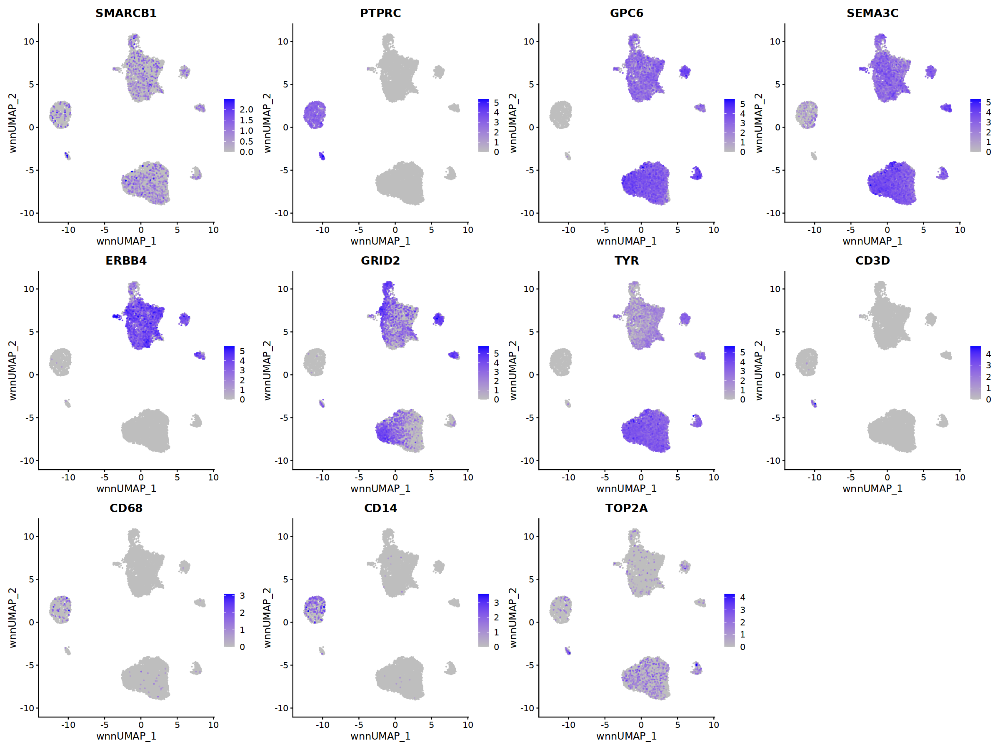

In [54]:
options(repr.plot.width = 20, repr.plot.height = 15)

vars2plot <- exp_genes_plot(c("SMARCB1","PTPRC","GPC6", "SEMA3C","ERBB4", 
                              "GRID2", "TYR","CD3D","CD68","CD14",
                              "TOP2A"), seurat_obj)

FeaturePlot(seurat_obj, reduction = "wnn.umap", feature=vars2plot, ncol = 4, 
            cols = c("gray", "blue"),order=T)

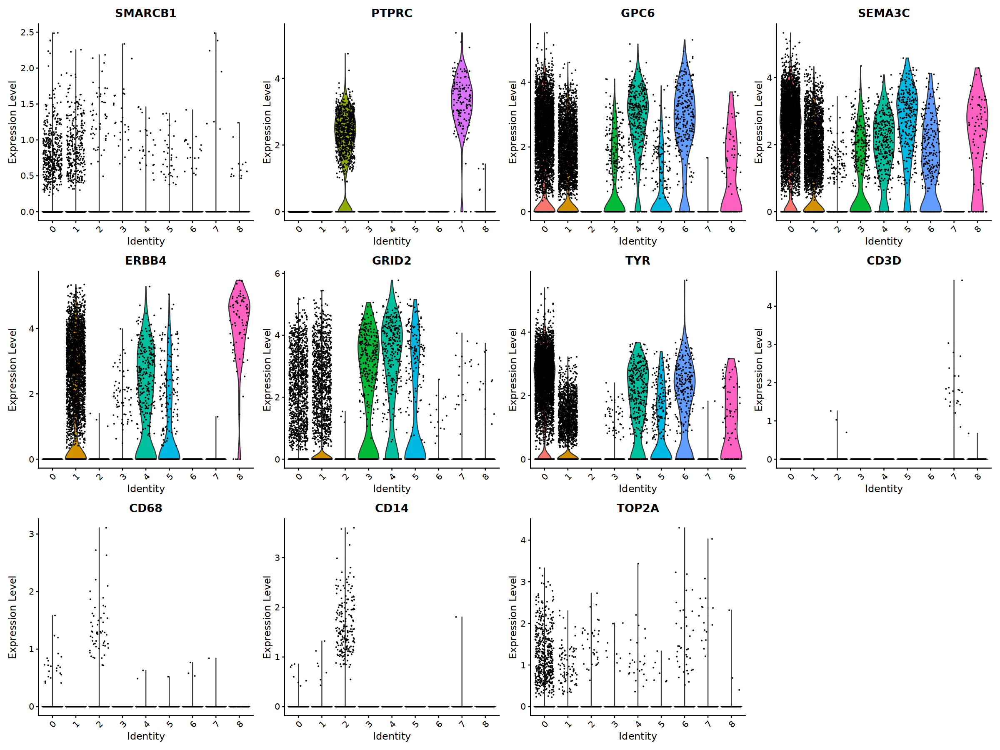

In [55]:
VlnPlot(seurat_obj, feature=vars2plot)

In [56]:
rna.markers %>% 
  dplyr::filter(cluster == "8") %>%
  dplyr::filter(p_val_adj<0.05) %>% 
  arrange(desc(avg_log2FC)) %>% head(n=15)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ADAMTS19,0.000000e+00,5.280484,0.854,0.024,0.000000e+00,8,ADAMTS19
GABRG31,1.019936e-227,3.929202,0.768,0.041,3.319689e-223,8,GABRG3
CCSER11,2.951898e-43,3.767571,0.805,0.289,9.607838e-39,8,CCSER1
AC008591.1,0.000000e+00,3.645495,0.805,0.022,0.000000e+00,8,AC008591.1
SEMA6D1,4.539992e-45,3.402507,0.732,0.195,1.477677e-40,8,SEMA6D
ERBB42,8.917043e-65,3.355005,0.951,0.278,2.902319e-60,8,ERBB4
AC007432.1,0.000000e+00,3.217988,0.524,0.002,0.000000e+00,8,AC007432.1
RTTN1,4.931520e-36,3.212192,0.841,0.426,1.605111e-31,8,RTTN
NRG32,3.429063e-58,3.089671,0.500,0.066,1.116091e-53,8,NRG3


### Rename

In [57]:
rename_clusters <- c("0"="Tumor TYR",
                     "1"="Tumor ERBB4",
                     "2"="Monocytes-Macrophages", 
                     "3"="Tumor GPC3",
                     "4"="Tumor GRID2",
                     "5"="Tumor EPHA6", 
                     "6"="Tumor COL25A1",
                     "7"="T-cells",
                     "8"="Tumor SEMA6D")

seurat_obj <- RenameIdents(object = seurat_obj, rename_clusters)
seurat_obj$clusters <- Idents(seurat_obj)

In [58]:
cols_keep <- c('nCount_ATAC', 'nFeature_ATAC', 'nCount_RNA', 'nFeature_RNA', 
               'is_cell', 'atac_fragments', 'atac_peak_region_fragments', 
               'fragments', 'mononucleosomal', 'nucleosome_free', 'reads_count', 
               'FRiP', 'caller', 'nucleosome_signal', 'nucleosome_percentile', 
               'TSS.enrichment', 'TSS.percentile', 'high.tss', 'pct_mt', 
               'pct_ribosomal', 'doublet_score', 'doublet_pred', 'doublet_score_atac',
               'doublet_enrichment_atac', 'S.Score', 'G2M.Score', 'Phase',
               'RNA.weight', 'ATAC.weight','nCount_RNA_decontx','nFeature_RNA_decontx', 
               'RNA_decontx.weight','seurat_clusters','clusters')

seurat_obj@meta.data <- seurat_obj@meta.data[,cols_keep] 

In [59]:
rna.markers <- rna.markers %>% 
      mutate(cluster = as.character(cluster)) %>% 
      mutate(annotation = rename_clusters[cluster])

In [60]:
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.csv")))

In [61]:
df_meta <- seurat_obj@meta.data

df_meta <- df_meta %>% 
      mutate(cell_groups = case_when(
      str_detect(clusters, "Tumor") ~ "Tumor",
      clusters == "Immune Cells" | clusters == "T-cells" | clusters == 'Plasma B-cell' ~ "Immune",
      str_detect(clusters, "Macrophage") ~ "Immune",
      TRUE ~ "Other stromal"))

seurat_obj@meta.data$cell_groups <- df_meta$cell_groups

In [62]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$cell_groups)
rna.markers <- FindAllMarkers(seurat_obj,only.pos = TRUE, min.pct = 0.1, logfc.threshold = 0.2)
readr::write_csv(rna.markers, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l1_anno_{patient}.csv")))

Calculating cluster Tumor

Calculating cluster Immune



In [63]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

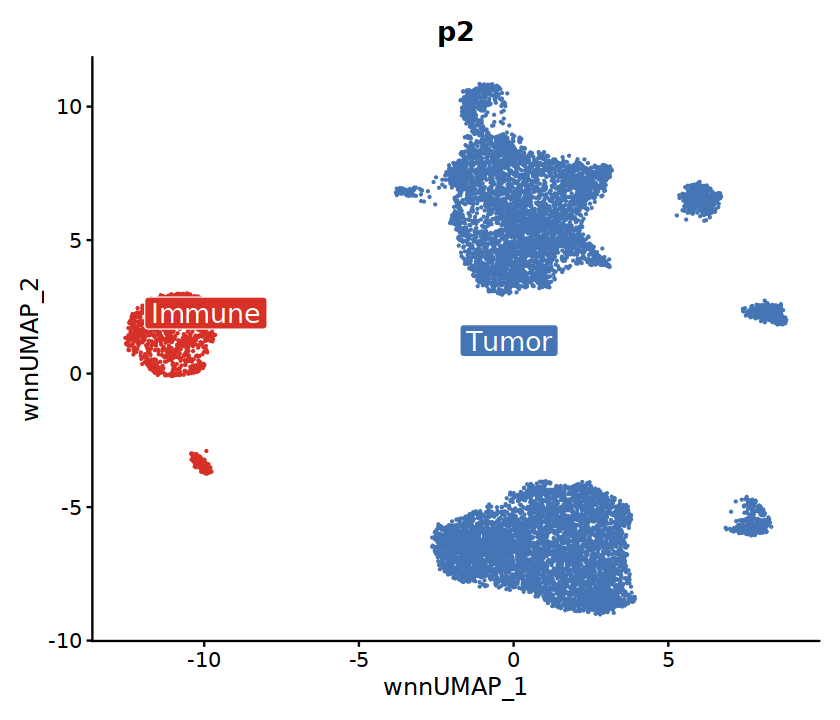

In [64]:
options(repr.plot.width = 7, repr.plot.height = 6)
l1 <-DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 5.5,
        repel = TRUE,
        label.color = as.list(color_labels),
        cols = c("Immune"="#d73027", "Other stromal"="#a6d96a","Tumor"="#4575b4")) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
l1

In [85]:
ggsave(plot = l1, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l1.svg")))

In [66]:
seurat_obj <- SetIdent(seurat_obj, value=seurat_obj@meta.data$clusters)

In [67]:
color_labels <- generate_color(unique(Idents(seurat_obj)))

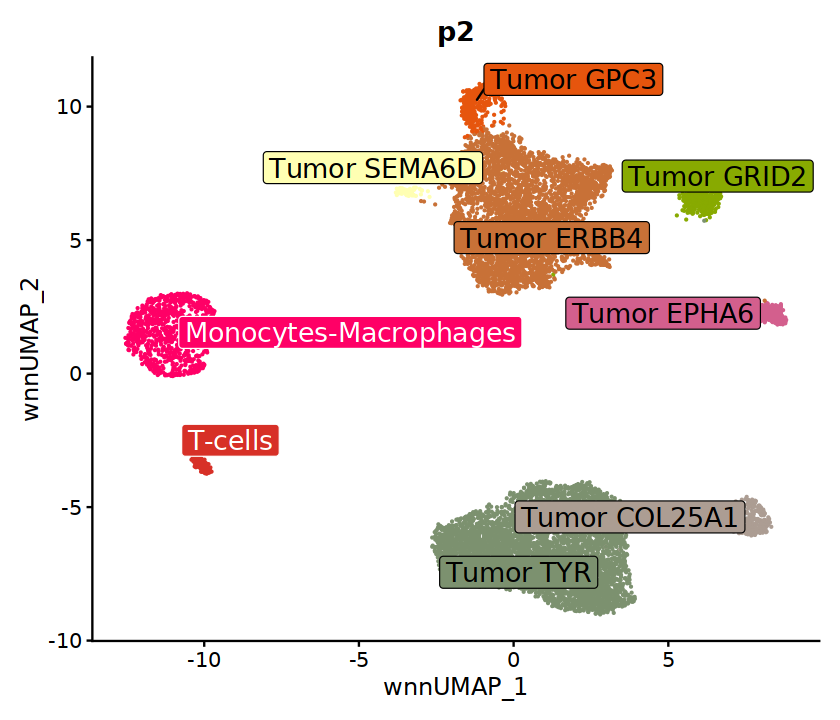

In [68]:
options(repr.plot.width = 7, repr.plot.height = 6)
p_clust <- DimPlot(seurat_obj, 
        reduction = "wnn.umap", 
        label = T,
        label.box = TRUE,
        label.size = 5.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))

p_clust

In [69]:
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP.svg")))
ggsave(plot = p_clust, width = 7, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_UMAP_l2.png")))

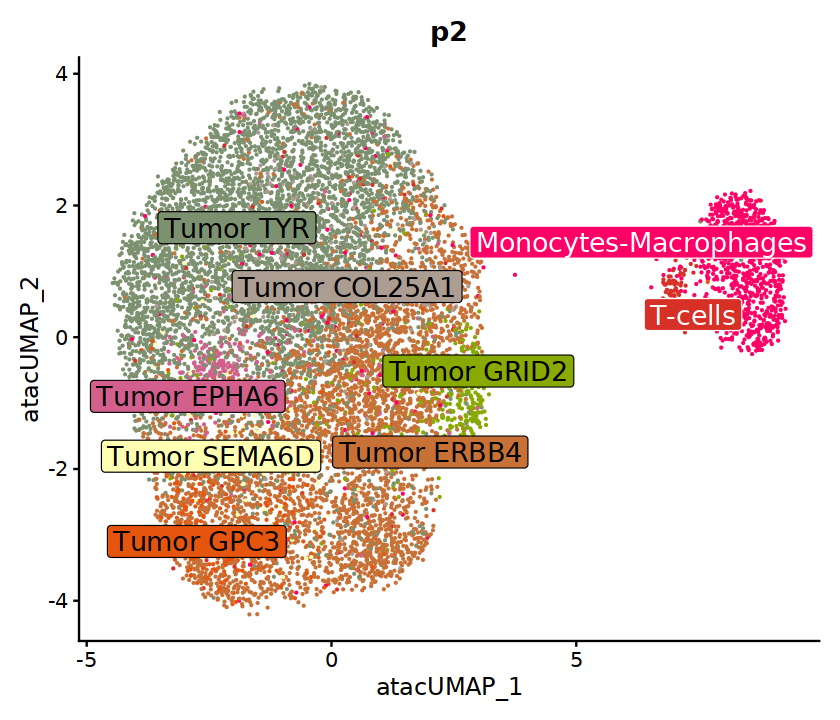

In [70]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(seurat_obj, 
        reduction = "umap.atac", 
        label = T,
        label.box = TRUE,
        label.size = 5.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))


In [71]:
# Calculate the variance explained 
stdev <- Stdev(seurat_obj, reduction = "pca")

var_explained <- (stdev^2) / sum(stdev^2) * 100

pc1_label <- paste0("PC1: ", round(var_explained[1], 2), "% var.")
pc2_label <- paste0("PC2: ", round(var_explained[2], 2), "% var.")

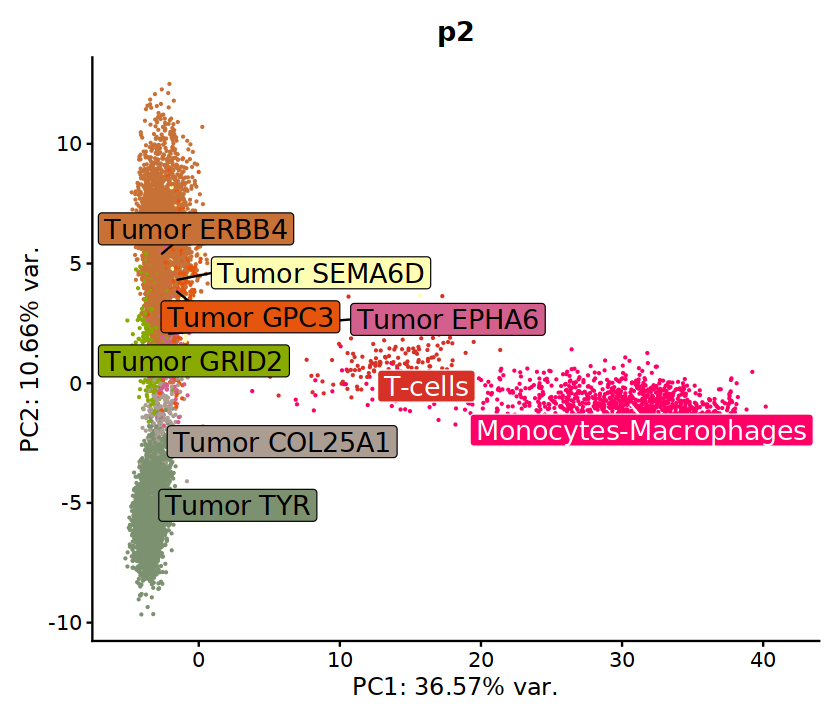

In [72]:
p_pca <- DimPlot(seurat_obj, 
        reduction = "pca", 
        label = T,
        label.box = TRUE,
        label.size = 5.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    xlab(pc1_label) +
    ylab(pc2_label) +
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_pca 

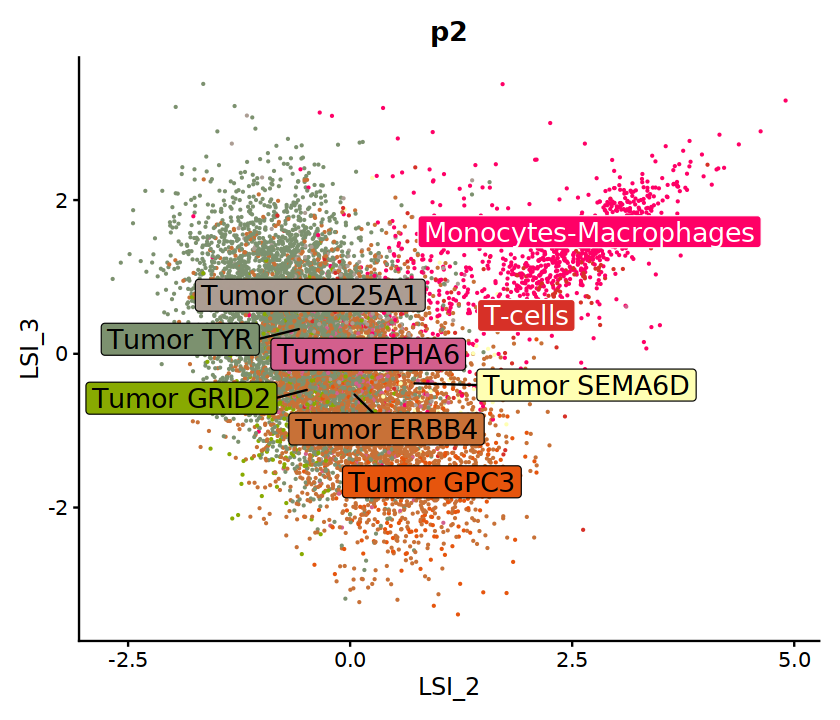

In [73]:
p_lsi <- DimPlot(seurat_obj, 
        reduction = "lsi.atac", 
        dims = c(2, 3),
        label = T,
        label.box = TRUE,
        label.size = 5.5,
        label.color = as.list(color_labels),
        repel = TRUE,
        cols = unlist(colors_list)) + 
    ggtitle(patient) + NoLegend() +
    theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"))
p_lsi

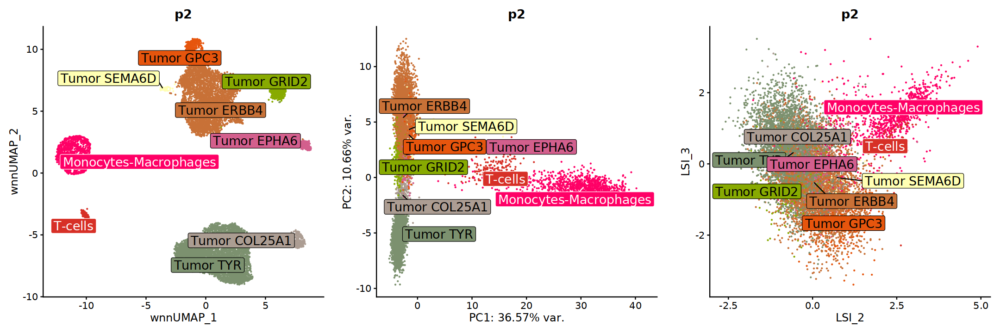

In [74]:
options(repr.plot.width = 18, repr.plot.height = 6)
cp <- cowplot::plot_grid(p_clust, p_pca, p_lsi,
                   align = "hv",
                   axis = "trbl",
                   ncol = 3,
                   nrow = 1)
cp

In [75]:
ggsave(plot = cp, width = 18, height = 6, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_reductions.png")))

Pseudo-bulk per cluster

In [76]:
var_name <- paste0("markers_", patient)
markers_clust <- get(var_name)

markers <- unlist(markers_clust, use.names = F)
markers <- c(c("GPC6", "SOX5", "SEMA5A","SEMA3C","OTX2-AS1"), markers) ## common markers to all clusters

In [77]:
Idents(seurat_obj) <- factor(Idents(seurat_obj), levels = names(markers_clust))

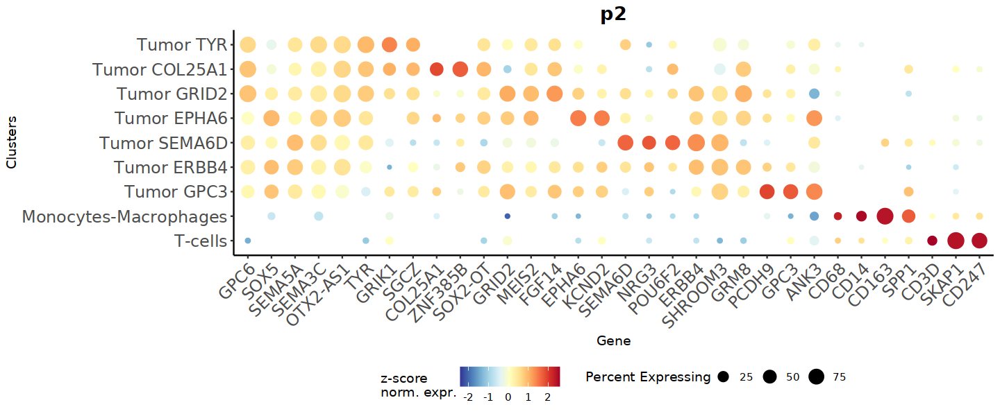

In [78]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp1 <- custom_dp(seurat_obj, markers, TRUE,patient)
dp1

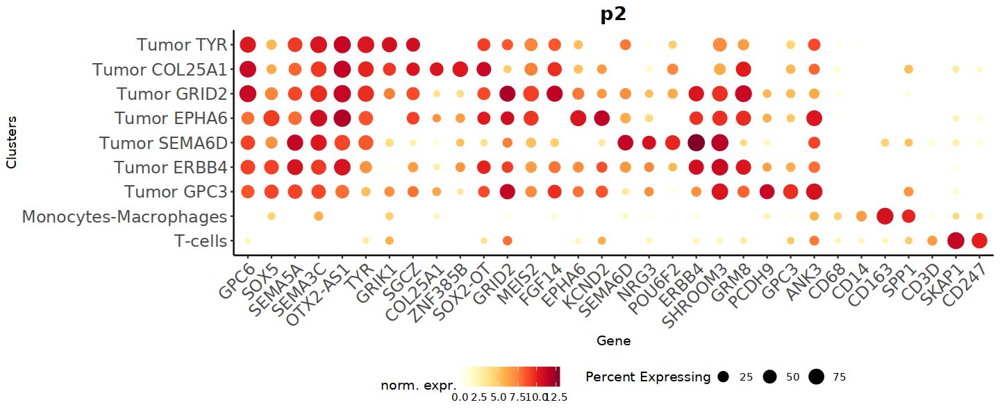

In [79]:
options(repr.plot.width = 12, repr.plot.height = 5, warn=-1,verbose = FALSE)
dp2 <- custom_dp(seurat_obj, markers, FALSE,patient)
dp2

In [80]:
ggsave(plot = dp1, width = 12, height = 5, dpi = 300, 
       file = here::here(glue::glue("{clust}/{plt_dir}/level_2/3.3.0-{patient}_dotplot.svg")))

## Save

In [81]:
# keep original metrics
seurat_obj$ncount_rna <- seurat_obj$nCount_RNA
seurat_obj$nfeature_rna <- seurat_obj$nFeature_RNA

In [82]:
seurat_obj$RNA <- NULL
seurat_obj[['RNA']] = seurat_obj[[assay_ch]]
DefaultAssay(seurat_obj) <- "RNA"
seurat_obj$RNA_decontx <- NULL

In [83]:
saveRDS(seurat_obj, here::here(glue::glue("{clust}/{robj_dir}/level_2/3.3.0-l2_anno_{patient}.rds")))

## Session

In [84]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] scater_1.22.0               scran_1.22.1               
 [3] scuttle_1.4.0               SingleCellExperiment_1.16.0
 [5] SummarizedExperiment_1.24.0 Biobase_2.54.0             
 [7] GenomicRanges_1.46.1        GenomeInfoDb_1.30.1        
 [9] IRanges_2.28.0    